# A Multi-Asset Market Risk Engine in R: EWMA, GARCH, DCC Correlations, Expected Shortfall, Monte Carlo and Machine-Learning VaR

Stocks and bonds hedged each other for twenty years and then fell together in 2022. A risk number built on fixed correlations understates the danger exactly when it matters. This notebook builds a daily market risk engine for a multi-asset portfolio with seven methods, from simple history to dynamic correlations and machine learning, and lets thirteen years of backtests decide which one to trust.

**What it does.** It computes the daily 99% VaR and 97.5% Expected Shortfall of a $100mm multi-asset portfolio (U.S., international and emerging equities, Treasuries, investment-grade and high-yield credit, gold and commodities) with seven methods, and backtests them out of sample from 2012:

1. historical simulation;
2. EWMA (RiskMetrics) covariance;
3. a GARCH model of the portfolio return;
4. a **DCC-GARCH** model of all eight assets (written from scratch);
5. a filtered-historical-simulation **Monte Carlo** on the DCC model;
6. a **quantile random forest**;
7. **XGBoost** quantile regression.

It reports today's risk split by asset (Euler allocation), how correlations behave in crises, and which method wins on regulatory backtests and on the Fissler–Ziegel loss.

**Data.** Yahoo Finance (eight ETFs since 2007, via `quantmod`) and FRED (VIX, Baa credit spread, Treasury term spread).

**Methods.** `rugarch` GJR-GARCH with skewed-t errors, DCC(1,1) by two-step quasi-maximum likelihood, multivariate filtered historical simulation, `ranger` quantile forests and `xgboost` quantile loss.

The backtests are Kupiec, Christoffersen and the Basel traffic light for VaR, the Acerbi–Székely test for ES, and Fissler–Ziegel FZ0 scoring.

**Key output.** VaR and ES today by method, component VaR by asset, rolling DCC correlations, backtest tables and loss rankings.

## 1. What a market risk engine has to do

A one-day **VaR** at 99% is the loss exceeded on one day in a hundred; **Expected Shortfall** at 97.5% is the average loss beyond the 97.5% quantile. Basel's FRTB moved the regulatory measure from VaR to ES because ES looks inside the tail.

A multi-asset portfolio adds a problem a single series does not have: **correlations change**. Stocks and bonds hedged each other from 2000 to 2021 and fell together in 2022; equity correlations jump towards one in crises. A static covariance understates risk exactly when it matters. The methods differ in how they handle this:

| method | volatility | correlation | tail shape |
|---|---|---|---|
| historical simulation | the last 500 days, unweighted | implicit in history | empirical |
| EWMA (λ = 0.94) | exponentially weighted | exponentially weighted | normal |
| portfolio GARCH | GJR-GARCH on the portfolio return | implicit, fixed weights | skewed t |
| DCC-GARCH | GJR-GARCH per asset | dynamic conditional correlation | multivariate t |
| DCC Monte Carlo (FHS) | GJR-GARCH per asset | DCC | empirical standardised shocks, resampled jointly |
| quantile random forest | learned from state variables | — | learned conditional quantiles |
| XGBoost quantile | learned from state variables | — | learned conditional quantiles |

## 2. Setup

In [1]:
# --- Packages (install once with `Rscript install_packages.R` from the repo
# root)
suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(patchwork)
  library(plotly)
  library(htmlwidgets)
  library(jsonlite)
})
options(warn = 1, dplyr.summarise.inform = FALSE, repr.plot.width = 14,
        repr.plot.height = 5, repr.plot.res = 110)
# plain-text tables in the notebook (no ANSI colour codes)
options(crayon.enabled = FALSE, cli.num_colors = 1)

# --- Folders and credentials
PROJECT_DIR <- getwd()
DATA_DIR <- file.path(PROJECT_DIR,
                      "data"); OUT_DIR <- file.path(PROJECT_DIR, "outputs")
dir.create(DATA_DIR,
           showWarnings = FALSE); dir.create(OUT_DIR, showWarnings = FALSE)
# look for .env in this folder and its parents (like python-dotenv)
find_env <- function(start = getwd()) {
  d <- normalizePath(start)
  repeat {
    f <- file.path(d, ".env")
    if (file.exists(f)) return(f)
    parent <- dirname(d)
    if (parent == d) return(NA_character_)
    d <- parent
  }
}
env_file <- find_env()
# tolerate a missing final newline
if (!is.na(env_file)) suppressWarnings(dotenv::load_dot_env(env_file))

# --- Cache helper: every download is stored in data/ and reused for 12 hours
cached <- function(name, fetch, max_age_hours = 12) {
  path <- file.path(DATA_DIR, paste0(name, ".rds"))
  if (file.exists(path) &&
      difftime(Sys.time(), file.mtime(path),
               units = "hours") < max_age_hours) return(readRDS(path))
  out <- tryCatch(fetch(), error = function(e) {
    if (file.exists(path)) { message(name, ": download failed (",
                                     conditionMessage(e),
                                     "); using cached copy"); return(readRDS(path)) }
    stop(e)
  })
  saveRDS(out, path)
  out
}

# --- Chart style (consistent palette across all charts)
PALETTE <- c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
             "#6250d6", "#e34948")
INK <- "#0b0b0b"; INK_2 <- "#52514e"; GRID <- "#e4e3df"; SURFACE <- "#fcfcfb"
STATUS <- c(green = "#1baf7a", amber = "#eda100", red = "#e34948")
theme_risk <- function() {
  theme_minimal(base_size = 11) +
    theme(plot.background = element_rect(fill = SURFACE, colour = NA),
          panel.background = element_rect(fill = SURFACE, colour = NA),
          panel.grid.major = element_line(colour = GRID),
            panel.grid.minor = element_blank(),
          plot.title = element_text(face = "bold", colour = INK, size = 12),
            plot.title.position = "plot",
          axis.text = element_text(colour = INK_2),
            axis.title = element_text(colour = INK_2),
          legend.position = "top", legend.title = element_blank())
}
theme_set(theme_risk())
save_fig <- function(p, name, width = 14,
                     height = 5) ggsave(file.path(
                         OUT_DIR, paste0(name, ".png")),
                                        p, width = width, height = height,
                                        dpi = 150, bg = SURFACE)

# Interactive dashboard as a single HTML file that loads plotly.js from a CDN
# (no pandoc needed)
save_plotly_html <- function(widget, name, title) {
  b <- plotly_build(widget)$x
  if (is.null(b$layout$height)) b$layout$height <- 900
  html <- sprintf('<!doctype html><html><head><meta charset="utf-8"><title>%s</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script></head>
<body style="background:%s;margin:0"><div id="dash" style="width:100%%;height:95vh"></div>
<script>var fig=%s;Plotly.newPlot("dash",fig.data,fig.layout,{responsive:true});</script></body></html>',
                  title, SURFACE,
                    toJSON(list(data = b$data, layout = b$layout),
                           auto_unbox = TRUE, null = "null", na = "null",
                           force = TRUE, digits = NA))
  writeLines(html, file.path(OUT_DIR, paste0(name, ".html")))
  message("Dashboard saved: outputs/", name, ".html")
}

suppressPackageStartupMessages({
  library(quantmod)
  library(fredr)
  library(rugarch)
  library(ranger)
  library(xgboost)
  library(mvtnorm)
})
if (Sys.getenv("FRED_API_KEY") == "") stop("FRED_API_KEY not found: create the .env file at the repo root")
fredr_set_key(Sys.getenv("FRED_API_KEY"))
TICKERS <- c("SPY", "EFA", "EEM", "TLT", "LQD", "HYG", "GLD", "DBC")
# portfolio weights
W <- c(SPY = 0.30, EFA = 0.10, EEM = 0.05, TLT = 0.20, LQD = 0.15, HYG = 0.05,
       GLD = 0.10, DBC = 0.05)
NOTIONAL <- 100e6
START <- as.Date("2007-05-01"); OOS_START <- as.Date("2012-01-01")
# trading days between re-estimations of the GARCH and DCC models
REFIT <- 63
HS_WINDOW <- 500; LAMBDA <- 0.94; N_MC <- 10000
set.seed(4)
cat(sprintf("R %s · rugarch %s · ranger %s · xgboost %s · run on %s\n",
            getRversion(), packageVersion("rugarch"), packageVersion("ranger"),
            packageVersion("xgboost"), Sys.Date()))

R 4.3.3 · rugarch 1.5.6 · ranger 0.18.0 · xgboost 3.2.1.1 · run on 2026-10-20


## 3. Data

Adjusted closes (dividends reinvested) for the eight ETFs come from Yahoo through `quantmod`, and daily log returns are computed on common trading days. The portfolio is rebalanced daily to fixed weights, so its return is the weighted sum of asset returns. That keeps the risk model's job clean: forecasting the distribution of w′r.

Three state variables from FRED feed the machine-learning models: the **VIX**, the **Baa–Treasury credit spread** and the **10-year minus 3-month term spread**.

In [2]:
prices <- cached("yahoo_prices", function() {
  do.call(
    merge,
    lapply(
      TICKERS,
      function(t) Ad(getSymbols(
        t,
        src = "yahoo", from = START, auto.assign = FALSE
      ))
    )
  )
}, max_age_hours = 24)
colnames(prices) <- TICKERS
prices <- na.omit(prices)
prices <- prices[index(prices) < Sys.Date()]
R <- na.omit(diff(log(prices)))
dates <- index(R)
Rm <- coredata(R)
# daily portfolio log return (fixed weights)
rp <- as.numeric(Rm %*% W[TICKERS])

fred_series <- function(id) {
  d <- fredr(series_id = id, observation_start = START - 30); xts(
    d$value,
    d$date
  )
}
st <- cached("fred_state",
  function() merge(vix = fred_series("VIXCLS"), baa = fred_series("BAA10Y"),
                   term = fred_series("T10Y3M")),
  max_age_hours = 24
)
st <- na.locf(merge(st, xts(, dates)))[dates]
cat(sprintf(
  "%d trading days · %s to %s · annualised portfolio vol %.1f%% · worst day %.2f%% (%s)\n",
  length(rp), first(dates), last(dates),
  100 * sd(rp) * sqrt(252), 100 * min(rp), dates[which.min(rp)]
))
round(cor(Rm[dates >= last(dates) - 730, ]), 2)

4898 trading days · 2007-05-02 to 2026-10-19 · annualised portfolio vol 10.6% · worst day -6.13% (2020-03-12)


,SPY,EFA,EEM,TLT,LQD,HYG,GLD,DBC
SPY,1.00,0.75,0.68,0.16,0.40,0.82,0.17,0.07
EFA,0.75,1.00,0.79,0.29,0.50,0.74,0.39,-0.04
EEM,0.68,0.79,1.00,0.18,0.37,0.61,0.40,0.01
TLT,0.16,0.29,0.18,1.00,0.90,0.44,0.12,-0.22
LQD,0.40,0.50,0.37,0.90,1.00,0.70,0.20,-0.18
HYG,0.82,0.74,0.61,0.44,0.70,1.00,0.22,0.00
GLD,0.17,0.39,0.40,0.12,0.20,0.22,1.00,0.27
DBC,0.07,-0.04,0.01,-0.22,-0.18,0.00,0.27,1.00


## 4. DCC-GARCH, written out

The dynamic conditional correlation model of Engle (2002) separates volatility from correlation:
1. each asset gets its own **GJR-GARCH(1,1)** with skewed-t errors (`rugarch`), giving conditional volatilities σ_{i,t} and standardised residuals z_{i,t} = r_{i,t}/σ_{i,t};
2. the residuals drive a **correlation process**: Q_t = (1 − a − b)·Q̄ + a·z_{t−1}z′_{t−1} + b·Q_{t−1}, and R_t = diag(Q_t)^{−½} Q_t diag(Q_t)^{−½};
3. a and b maximise the Gaussian correlation log-likelihood −½ Σ_t [ln|R_t| + z′_t R_t^{−1} z_t − z′_t z_t], with a, b ≥ 0 and a + b < 1.

The covariance forecast is H_t = D_t R_t D_t with D_t = diag(σ_t). The code below implements steps 2–3 directly; it avoids extra package dependencies and keeps every step visible.

In [3]:
spec_u <- ugarchspec(
  variance.model = list(model = "gjrGARCH", garchOrder = c(1, 1)),
  mean.model = list(armaOrder = c(0, 0), include.mean = TRUE),
  distribution.model = "sstd"
)

dcc_recursion <- function(z, a, b, Qbar) {
  n <- nrow(z); k <- ncol(z)
  Q <- Qbar; Rl <- vector("list", n); ll <- 0
  for (t in seq_len(n)) {
    if (t > 1) Q <- (1 - a - b) * Qbar + a * tcrossprod(z[t - 1, ]) + b * Q
    d <- 1 / sqrt(diag(Q)); Rt <- Q * outer(d, d)
    Rl[[t]] <- Rt
    ch <- chol(Rt)
    zz <- backsolve(ch, z[t, ], transpose = TRUE)
    ll <- ll - 0.5 * (2 * sum(log(diag(ch))) + sum(zz^2) - sum(z[t, ]^2))
  }
  list(R = Rl, ll = ll, Q = Q)
}

fit_dcc <- function(z) {
  Qbar <- cor(z)
  obj <- function(p) {
    if (p[1] < 0 || p[2] < 0 ||
      sum(p) >= 0.999) return(1e10); -dcc_recursion(z, p[1], p[2], Qbar)$ll
  }
  o <- optim(c(0.02, 0.95), obj,
    method = "Nelder-Mead",
    control = list(maxit = 300, reltol = 1e-8)
  )
  list(a = o$par[1], b = o$par[2], Qbar = Qbar, ll = -o$value)
}

# --- one fit on the whole sample, to show the parameters and today's
# correlation
t0 <- Sys.time()
ufits <- lapply(
  seq_along(TICKERS),
  function(i) ugarchfit(spec_u, Rm[, i] * 100,
    solver = "hybrid"
  )
)
sig_full <- sapply(ufits, function(f) as.numeric(sigma(f))) / 100
mu_full <- sapply(ufits, function(f) coef(f)["mu"]) / 100
z_full <- (Rm - matrix(mu_full, nrow(Rm), length(TICKERS), byrow = TRUE)) /
  sig_full
dcc_full <- fit_dcc(z_full)
rec_full <- dcc_recursion(z_full, dcc_full$a, dcc_full$b, dcc_full$Qbar)
garch_tab <- t(sapply(
  ufits,
  function(f) coef(f)[c(
    "omega", "alpha1", "beta1", "gamma1", "skew",
    "shape"
  )]
))
rownames(garch_tab) <- TICKERS
cat(sprintf(
  "DCC: a = %.4f, b = %.4f (persistence %.4f) · estimated in %.0fs\n",
  dcc_full$a, dcc_full$b, dcc_full$a + dcc_full$b,
  as.numeric(difftime(Sys.time(), t0, units = "secs"))
))
round(garch_tab, 4)

DCC: a = 0.0247, b = 0.9657 (persistence 0.9904) · estimated in 31s


,omega,alpha1,beta1,gamma1,skew,shape
SPY,0.0257,0.0000,0.8538,0.2611,0.8413,6.5778
EFA,0.0206,0.0125,0.8967,0.1561,0.8430,7.3181
EEM,0.0337,0.0210,0.9061,0.1151,0.8731,9.6606
TLT,0.0099,0.0666,0.9317,-0.0179,0.9404,15.6808
LQD,0.0035,0.0504,0.9043,0.0520,0.8859,8.3961
HYG,0.0020,0.0334,0.8751,0.1905,0.8834,5.7903
GLD,0.0085,0.0663,0.9476,-0.0360,0.9401,5.3399
DBC,0.0086,0.0496,0.9359,0.0205,0.8852,7.8568


In [4]:
pair_cor <- function(i, j) sapply(rec_full$R, function(m) m[i, j])
corr_ts <- tibble(
  date = dates, `SPY–TLT (stocks vs Treasuries)` = pair_cor(1, 4),
  `SPY–EFA (US vs international)` = pair_cor(1, 2),
  `SPY–HYG (stocks vs high yield)` = pair_cor(1, 6),
  `SPY–GLD (stocks vs gold)` = pair_cor(1, 7)
)
crisis <- tibble(
  period = c("GFC (Sep-08 – Mar-09)", "Euro crisis (Aug-11)", "Covid (Mar-20)",
             "2022 rate shock", "Apr-25 tariff shock", "last 3 months"),
  from = as.Date(c("2008-09-01", "2011-08-01", "2020-02-20", "2022-01-01",
                   "2025-04-01", as.character(last(dates) - 91))),
  to = as.Date(c(
    "2009-03-31", "2011-08-31", "2020-04-15", "2022-10-31",
    "2025-04-30", as.character(last(dates))
  ))
)
crisis_tab <- bind_cols(
  crisis["period"],
  map_dfr(seq_len(nrow(crisis)), function(k) {
    sel <- corr_ts$date >= crisis$from[k] & corr_ts$date <= crisis$to[k]
    summarise(corr_ts[sel, -1], across(everything(), mean))
  })
)
crisis_tab |> mutate(across(-period, \(v) round(v, 2)))

period,SPY–TLT (stocks vs Treasuries),SPY–EFA (US vs international),SPY–HYG (stocks vs high yield),SPY–GLD (stocks vs gold)
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
GFC (Sep-08 – Mar-09),-0.45,0.90,0.48,-0.03
Euro crisis (Aug-11),-0.47,0.90,0.80,-0.24
Covid (Mar-20),-0.50,0.90,0.82,-0.11
2022 rate shock,-0.07,0.85,0.77,0.07
Apr-25 tariff shock,-0.09,0.71,0.82,0.19
last 3 months,0.22,0.79,0.73,0.34


## 5. Rolling out-of-sample forecasts, 2012 to today

Every forecast for day t uses only data up to day t − 1:
- **HS:** the 1% quantile and the 2.5% tail mean of the last 500 portfolio returns.
- **EWMA:** σ²_t = λσ²_{t−1} + (1 − λ)(w′r_{t−1})², normal quantiles. This is equivalent to applying the RiskMetrics covariance to the fixed weights.
- **Portfolio GARCH:** GJR-GARCH-sstd on the portfolio return, re-estimated every 63 days on an expanding window and filtered daily in between.
- **DCC-t:** the per-asset GARCH and DCC parameters are re-estimated every 63 days and filtered daily. The portfolio σ_p,t = √(w′H_t w) is then scaled by a Student t, whose degrees of freedom are fitted to the standardised portfolio residuals.
- **DCC Monte Carlo (FHS):** 10,000 draws of past standardised, *decorrelated* shock vectors (the full eight-asset vector of a past day, so joint tail behaviour is kept) are re-coloured with today's H_t^{½}.

**Quantile random forest and XGBoost:** trained on all data up to each yearly re-estimation date. The features are the EWMA volatility, 5- and 21-day realised volatility, 1- and 5-day portfolio returns, distance from the 1-year high, the VIX, the credit spread and its 5-day change, and the term spread. They predict the 1% quantile directly; ES is the mean of predicted quantiles from 0.25% to 2.5%.

In [5]:
n <- length(rp); oos <- which(dates >= OOS_START)
# 99% VaR, 97.5% ES and the 97.5% VaR used by ES tests
VaR <- matrix(NA, n, 7); ES <- matrix(NA, n, 7); V975 <- matrix(NA, n, 7)
MODELS <- c("historical simulation", "EWMA normal", "portfolio GARCH", "DCC-t",
            "DCC Monte Carlo (FHS)", "quantile random forest",
            "XGBoost quantile")
colnames(VaR) <- colnames(ES) <- MODELS
zq <- qnorm(0.01); es_n <- dnorm(qnorm(0.025)) / 0.025

# --- 1. historical simulation and 2. EWMA
ew <- numeric(n); ew[1] <- var(rp[1:250])
for (t in 2:n) ew[t] <- LAMBDA * ew[t - 1] + (1 - LAMBDA) * rp[t - 1]^2
for (t in oos) {
  h <- rp[(t - HS_WINDOW):(t - 1)]
  VaR[t, 1] <- -quantile(h, 0.01, type = 7); V975[t, 1] <- -quantile(h, 0.025,
      type = 7); ES[t, 1] <- -mean(h[h <= quantile(h, 0.025)])
}
VaR[oos, 2] <- -zq * sqrt(ew[oos]); V975[oos, 2] <- -qnorm(0.025) *
  sqrt(ew[oos]); ES[oos, 2] <- es_n * sqrt(ew[oos])

# --- 3–5. portfolio GARCH, DCC-t and DCC Monte Carlo, re-estimated every REFIT
# days
refits <- oos[seq(1, length(oos), by = REFIT)]
t0 <- Sys.time()
# ES of a standardised skewed t by quadrature on quantiles
qsstd_es <- function(skew, shape, p = 0.025, m = 4000) {
  u <- (seq_len(m) - 0.5) / m * p
  -mean(qdist("sstd", u, mu = 0, sigma = 1, skew = skew, shape = shape))
}
for (k in seq_along(refits)) {
  t1 <- refits[k]; t2 <- if (k < length(refits)) refits[k + 1] - 1 else n
  idx <- 1:(t1 - 1)
  # portfolio GARCH
  pf <- ugarchfit(spec_u, rp[idx] * 100, solver = "hybrid")
  pspec <- spec_u; setfixed(pspec) <- as.list(coef(pf))
  pfl <- ugarchfilter(pspec, rp[1:t2] * 100)
  s_p <- as.numeric(sigma(pfl))[t1:t2] / 100; m_p <- coef(pf)["mu"] / 100
  q_p <- qdist("sstd", 0.01, mu = 0, sigma = 1, skew = coef(pf)["skew"],
               shape = coef(pf)["shape"])
  VaR[t1:t2, 3] <- -(m_p + q_p * s_p)
  V975[t1:t2, 3] <- -(m_p +
       qdist("sstd", 0.025, mu = 0, sigma = 1, skew = coef(pf)["skew"],
             shape = coef(pf)["shape"]) *
       s_p)
  ES[t1:t2, 3] <- -m_p + s_p * qsstd_es(coef(pf)["skew"], coef(pf)["shape"])
  # per-asset GARCH filtered through t2
  sig <- matrix(NA, t2, length(TICKERS)); mu <- numeric(length(TICKERS))
  for (i in seq_along(TICKERS)) {
    f <- tryCatch(ugarchfit(spec_u, Rm[idx, i] * 100, solver = "hybrid"),
                  error = function(e) NULL)
    if (is.null(f) || f@fit$convergence != 0) f <- ugarchfit(spec_u,
        Rm[idx, i] * 100, solver = "solnp")
    sp <- spec_u; setfixed(sp) <- as.list(coef(f))
    sig[, i] <- as.numeric(sigma(ugarchfilter(sp, Rm[1:t2, i] * 100))) / 100
    mu[i] <- coef(f)["mu"] / 100
  }
  z <- (Rm[1:t2, ] - matrix(mu, t2, length(TICKERS), byrow = TRUE)) / sig
  dfit <- fit_dcc(z[idx, ])
  rec <- dcc_recursion(z, dfit$a, dfit$b, dfit$Qbar)
  # Student-t degrees of freedom for the standardised portfolio return in the
  # estimation window
  sp_hist <- sapply(idx,
                    function(t) sqrt(drop(t(
                        W * sig[t, ]) %*% rec$R[[t]] %*% (W * sig[t, ]))))
  zp <- (rp[idx] - sum(W * mu)) / sp_hist
  nu <- optimize(function(v) -sum(dt(zp * sqrt(v / (v - 2)), v, log = TRUE) +
                                  0.5 * log(v / (v - 2))),
                 c(2.5, 60))$minimum
  qt_ <- qt(0.01, nu) * sqrt((nu - 2) / nu)
  es_t <- (dt(qt(0.025, nu), nu) / 0.025) *
    ((nu + qt(0.025, nu)^2) / (nu - 1)) * sqrt((nu - 2) / nu)
  # decorrelated shocks of the estimation window, for the FHS Monte Carlo
  E <- t(sapply(idx,
                function(t) backsolve(chol(rec$R[[t]]), z[t, ],
                                      transpose = TRUE)))
  for (t in t1:t2) {
    Ht_half <- t(chol(rec$R[[t]])) * sig[t, ] # rows scaled: D_t · chol(R_t)'
    s_pt <- sqrt(sum((t(Ht_half) %*% W)^2))
    VaR[t, 4] <- -(sum(W * mu) + qt_ * s_pt); V975[t, 4] <- -(sum(W * mu) +
        qt(0.025, nu) * sqrt((nu - 2) / nu) * s_pt); ES[t, 4] <- -sum(W * mu) +
      es_t * s_pt
    draws <- E[sample.int(nrow(E), N_MC, replace = TRUE), ] %*% t(Ht_half)
    sim <- drop(draws %*% W) + sum(W * mu)
    qv <- quantile(sim, c(0.01, 0.025)); VaR[t, 5] <- -qv[1]; V975[t,
                   5] <- -qv[2]; ES[t, 5] <- -mean(sim[sim <= qv[2]])
  }
}
cat(sprintf("GARCH / DCC: %d re-estimations in %.0f minutes\n", length(refits),
            as.numeric(difftime(Sys.time(), t0, units = "mins"))))

GARCH / DCC: 60 re-estimations in 23 minutes


In [6]:
# --- 6–7. machine-learning quantile models
roll_sd <- function(x, k) {
  out <- rep(
    NA,
    length(x)
  ); for (t in k:length(x)) out[t] <- sd(x[(
    t - k + 1):t]); out
}
cum <- cumsum(rp)
hi252 <- sapply(seq_along(cum), function(t) max(cum[max(1, t - 251):t]))
FE <- tibble(
  ewma = sqrt(ew), rv5 = roll_sd(rp, 5), rv21 = roll_sd(rp, 21), r1 = rp,
  r5 = stats::filter(rp, rep(1, 5), sides = 1),
  dd = cum - hi252, vix = as.numeric(st$vix), baa = as.numeric(st$baa),
  dbaa = as.numeric(st$baa) - lag(as.numeric(st$baa), 5),
  term = as.numeric(st$term)
) |> mutate(r5 = as.numeric(r5))
# features known at t − 1 for the return of day t
X <- as.matrix(FE)[c(NA, 1:(n - 1)), ]
Y <- rp
taus <- seq(0.0025, 0.025, by = 0.0025)
year_starts <- oos[!duplicated(format(dates[oos], "%Y"))]
for (k in seq_along(year_starts)) {
  t1 <- year_starts[k]; t2 <- if (k < length(year_starts)) year_starts[k + 1] -
    1 else n
  tr <- which(complete.cases(X) & seq_len(n) < t1); te <- t1:t2
  qrf <- ranger(
    x = X[tr, ], y = Y[tr], num.trees = 500, min.node.size = 25,
    quantreg = TRUE, seed = 4
  )
  qp <- predict(qrf, X[te, , drop = FALSE],
    type = "quantiles",
    quantiles = c(0.01, taus)
  )$predictions
  VaR[te, 6] <- -qp[, 1]; V975[te, 6] <- -qp[, ncol(qp)]; ES[
    te,
    6
  ] <- -rowMeans(qp[, -1])
  dtr <- xgb.DMatrix(X[tr, ], label = Y[tr])
  bst <- xgb.train(params = list(
    objective = "reg:quantileerror", quantile_alpha = c(0.01, taus),
    eta = 0.03, max_depth = 3,
    min_child_weight = 20, subsample = 0.8, nthread = 2
  ), data = dtr, nrounds = 400, verbose = 0)
  qx <- predict(bst, X[te, , drop = FALSE])
  # fix quantile crossing: column j is now the j-th smallest quantile
  qx <- t(apply(qx, 1, sort))
  a_sorted <- sort(c(0.01, taus))
  VaR[te, 7] <- -qx[, which(a_sorted == 0.01)[1]]; V975[te, 7] <- -qx[
    ,
    ncol(qx)
  ]
  # the ten tail quantiles from 0.25% to 2.5%
  ES[te, 7] <- -rowMeans(qx[, -which(a_sorted == 0.01)[1]])
}
cat("ML quantile models re-estimated", length(year_starts), "times\n")

ML quantile models re-estimated 15 times


## 6. Backtests and scoring

**VaR backtests** (on the 99% VaR):
- **Kupiec:** is the exception rate 1%?
- **Christoffersen independence:** do exceptions cluster? An exception yesterday should not make one more likely today.
- **Basel traffic light:** exceptions in each rolling 250-day window. Green is ≤ 4, yellow 5–9, red ≥ 10. The table shows the share of windows in each zone.

**ES backtest:** the Acerbi–Székely Z₂ statistic, Z₂ = Σ_t (L_t·I_t)/(N·α·ES_t) − 1, where L_t is the loss, I_t the exception indicator at the 97.5% VaR, N the number of days and α = 2.5%. It is negative when the realised tail is worse than forecast; values below about −0.70 fail at the 5% level (Basel's 97.5% calibration).

**Joint scoring:** the **FZ0 loss** of Fissler and Ziegel (Patton, Ziegel and Chen, 2019) is a consistent scoring function for the pair (97.5% VaR, 97.5% ES). Lower is better, and the average over days ranks models without the arbitrariness of choosing one test. Every model forecasts its own 97.5% quantile alongside the 99% VaR, so both the Z₂ test and FZ0 use each model's exact 97.5% VaR.

In [7]:
loss <- -rp
kupiec <- function(I, p = 0.01) {
  x <- sum(I); N <- length(I); ph <- x / N
  lr <- -2 *
    (x * log(p) + (N - x) * log(1 - p) - ifelse(x > 0, x * log(ph), 0) -
      ifelse(N - x > 0, (N - x) * log(1 - ph), 0)); 1 -
    pchisq(lr, 1)
}
christ <- function(I) {
  a <- I[-length(I)]; b <- I[-1]
  n00 <- sum(!a & !b); n01 <- sum(!a & b); n10 <- sum(a & !b); n11 <- sum(a &
    b)
  p01 <- n01 /
    (n00 + n01); p11 <- ifelse(n10 + n11 > 0, n11 / (n10 + n11),
    0
  ); p <- (n01 + n11) /
    (n00 + n01 + n10 + n11)
  ll0 <- (n00 + n10) * log(1 - p) + (n01 + n11) * log(p)
  ll1 <- n00 * log(1 - p01) + n01 * log(p01) +
    ifelse(n10 > 0, n10 * log(1 - p11), 0) + ifelse(n11 > 0, n11 * log(p11), 0)
  1 - pchisq(-2 * (ll0 - ll1), 1)
}
# y = return, v = VaR as a (negative) return quantile, e = ES as a (negative)
# return
fz0 <- function(y, v, e, a = 0.025) {
  -((y <= v) * (v - y)) / (a * e) + v / e + log(-e) - 1
}
tl_zone <- function(I) {
  w <- zoo::rollsum(I, 250, align = "right"); c(
    green = mean(w <= 4),
    yellow = mean(w >= 5 & w <= 9), red = mean(w >= 10)
  )
}
BT <- map_dfr(seq_along(MODELS), function(m) {
  ok <- oos[!is.na(VaR[oos, m])]
  I <- loss[ok] > VaR[ok, m]
  v975 <- V975[ok, m]
  I975 <- loss[ok] > v975
  z2 <- sum(loss[ok] * I975 / ES[ok, m]) / (length(ok) * 0.025) - 1
  zone <- tl_zone(I)
  tibble(
    model = MODELS[m], days = length(ok), exceptions = sum(I),
    `rate (%)` = 100 * mean(I), `Kupiec p` = kupiec(I),
    `Christoffersen p` = christ(I),
    `green (%)` = 100 * zone["green"], `yellow (%)` = 100 * zone["yellow"],
    `red (%)` = 100 * zone["red"],
    `ES Z2` = z2, `mean VaR ($k)` = mean(VaR[ok, m]) * NOTIONAL / 1e3,
    `mean ES ($k)` = mean(ES[ok, m]) * NOTIONAL / 1e3,
    FZ0 = mean(fz0(rp[ok], -v975, -ES[ok, m]))
  )
})
BT |> mutate(across(where(is.numeric), \(v) round(v, 3)))

model,days,exceptions,rate (%),Kupiec p,Christoffersen p,green (%),yellow (%),red (%),ES Z2,mean VaR ($k),mean ES ($k),FZ0
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
historical simulation,3720,38,1.022,0.895,0.000,79.314,15.673,5.013,0.120,1503.330,1625.537,-4.057
EWMA normal,3720,73,1.962,0.000,0.003,39.268,58.600,2.132,0.685,1194.774,1200.657,-4.165
portfolio GARCH,3720,38,1.022,0.895,0.062,89.311,10.689,0.000,-0.029,1430.294,1471.157,-4.260
DCC-t,3720,51,1.371,0.031,0.037,72.112,27.888,0.000,0.269,1297.915,1335.081,-4.268
DCC Monte Carlo (FHS),3720,36,0.968,0.842,0.362,92.769,7.231,0.000,-0.004,1394.541,1452.403,-4.270
quantile random forest,3720,32,0.860,0.380,0.031,91.760,8.240,0.000,-0.227,1640.659,1582.635,-4.158
XGBoost quantile,3720,56,1.505,0.004,0.011,72.198,24.143,3.659,0.399,1308.684,1256.114,-4.193


**By sub-period.** Exception rates in calm and stressed years show which models adapt.

In [8]:
periods <- list(
  `2012–2019` = c("2012-01-01", "2019-12-31"),
  `2020 (Covid)` = c("2020-01-01", "2020-12-31"),
  `2021` = c("2021-01-01", "2021-12-31"),
  `2022 (rates)` = c("2022-01-01", "2022-12-31"),
  `2023–today` = c("2023-01-01", as.character(last(dates)))
)
SUB <- map_dfr(names(periods), function(p) {
  sel <- oos[dates[oos] >= as.Date(periods[[p]][1]) &
    dates[oos] <= as.Date(periods[[p]][2])]
  as_tibble(t(sapply(seq_along(MODELS), function(m) 100 *
                     mean(loss[sel] > VaR[sel, m], na.rm = TRUE))),
    .name_repair = ~MODELS
  ) |>
    mutate(period = p, .before = 1)
})
SUB |> mutate(across(-period, \(v) round(v, 2)))

period,historical simulation,EWMA normal,portfolio GARCH,DCC-t,DCC Monte Carlo (FHS),quantile random forest,XGBoost quantile
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2012–2019,0.75,1.74,0.65,0.99,0.75,0.40,0.94
2020 (Covid),3.95,3.95,2.77,2.77,2.77,2.37,4.35
2021,0.00,1.98,1.98,1.98,1.19,1.59,1.98
2022 (rates),1.99,3.19,0.40,1.99,0.80,1.59,2.79
2023–today,0.84,1.58,1.26,1.47,0.95,1.05,1.47


## 7. Today's risk and where it comes from

The DCC model's covariance for tomorrow allocates VaR to assets by **Euler allocation**: component VaR_i = [w_i·(H w)_i / σ_p²] × VaR, which sums to the total. A component larger than its weight means the asset adds more than its share of risk. A negative component means the asset hedges the rest of the portfolio.

In [9]:
tl <- n
Ht <- diag(sig[tl, ]) %*% rec$R[[tl]] %*% diag(sig[tl, ])
sp_now <- sqrt(drop(t(W) %*% Ht %*% W))
contrib <- W * drop(Ht %*% W) / sp_now^2
TODAY <- tibble(model = MODELS, `1-day 99% VaR ($k)` = VaR[tl, ] * NOTIONAL /
  1e3, `1-day 97.5% ES ($k)` = ES[tl, ] * NOTIONAL / 1e3)
COMP <- tibble(
  asset = TICKERS, weight = W[TICKERS], `share of DCC VaR` = contrib,
  `component VaR ($k)` = contrib * VaR[tl, 4] * NOTIONAL / 1e3,
  `vol (ann., %)` = 100 * sig[tl, ] * sqrt(252)
)
cat(sprintf("Forecast for the day after %s\n", last(dates)))
print(TODAY |> mutate(across(where(is.numeric), \(v) round(v, 0))))
COMP |> mutate(across(where(is.numeric), \(v) round(v, 3)))

Forecast for the day after 2026-10-19


# A tibble: 7 × 3
  model                  `1-day 99% VaR ($k)` `1-day 97.5% ES ($k)`
  <chr>                                 <dbl>                 <dbl>
1 historical simulation                  1826                  1809
2 EWMA normal                            1131                  1136
3 portfolio GARCH                        1395                  1436
4 DCC-t                                  1399                  1439
5 DCC Monte Carlo (FHS)                  1559                  1626
6 quantile random forest                 1504                  1531
7 XGBoost quantile                       1236                  1238


asset,weight,share of DCC VaR,component VaR ($k),"vol (ann., %)"
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
SPY,0.30,0.417,582.911,14.556
EFA,0.10,0.118,164.528,12.757
EEM,0.05,0.100,139.912,24.452
TLT,0.20,0.127,178.131,11.398
LQD,0.15,0.068,94.496,6.067
HYG,0.05,0.025,34.453,5.488
GLD,0.10,0.155,216.895,20.853
DBC,0.05,-0.009,-12.318,16.375


## 8. Charts and dashboard

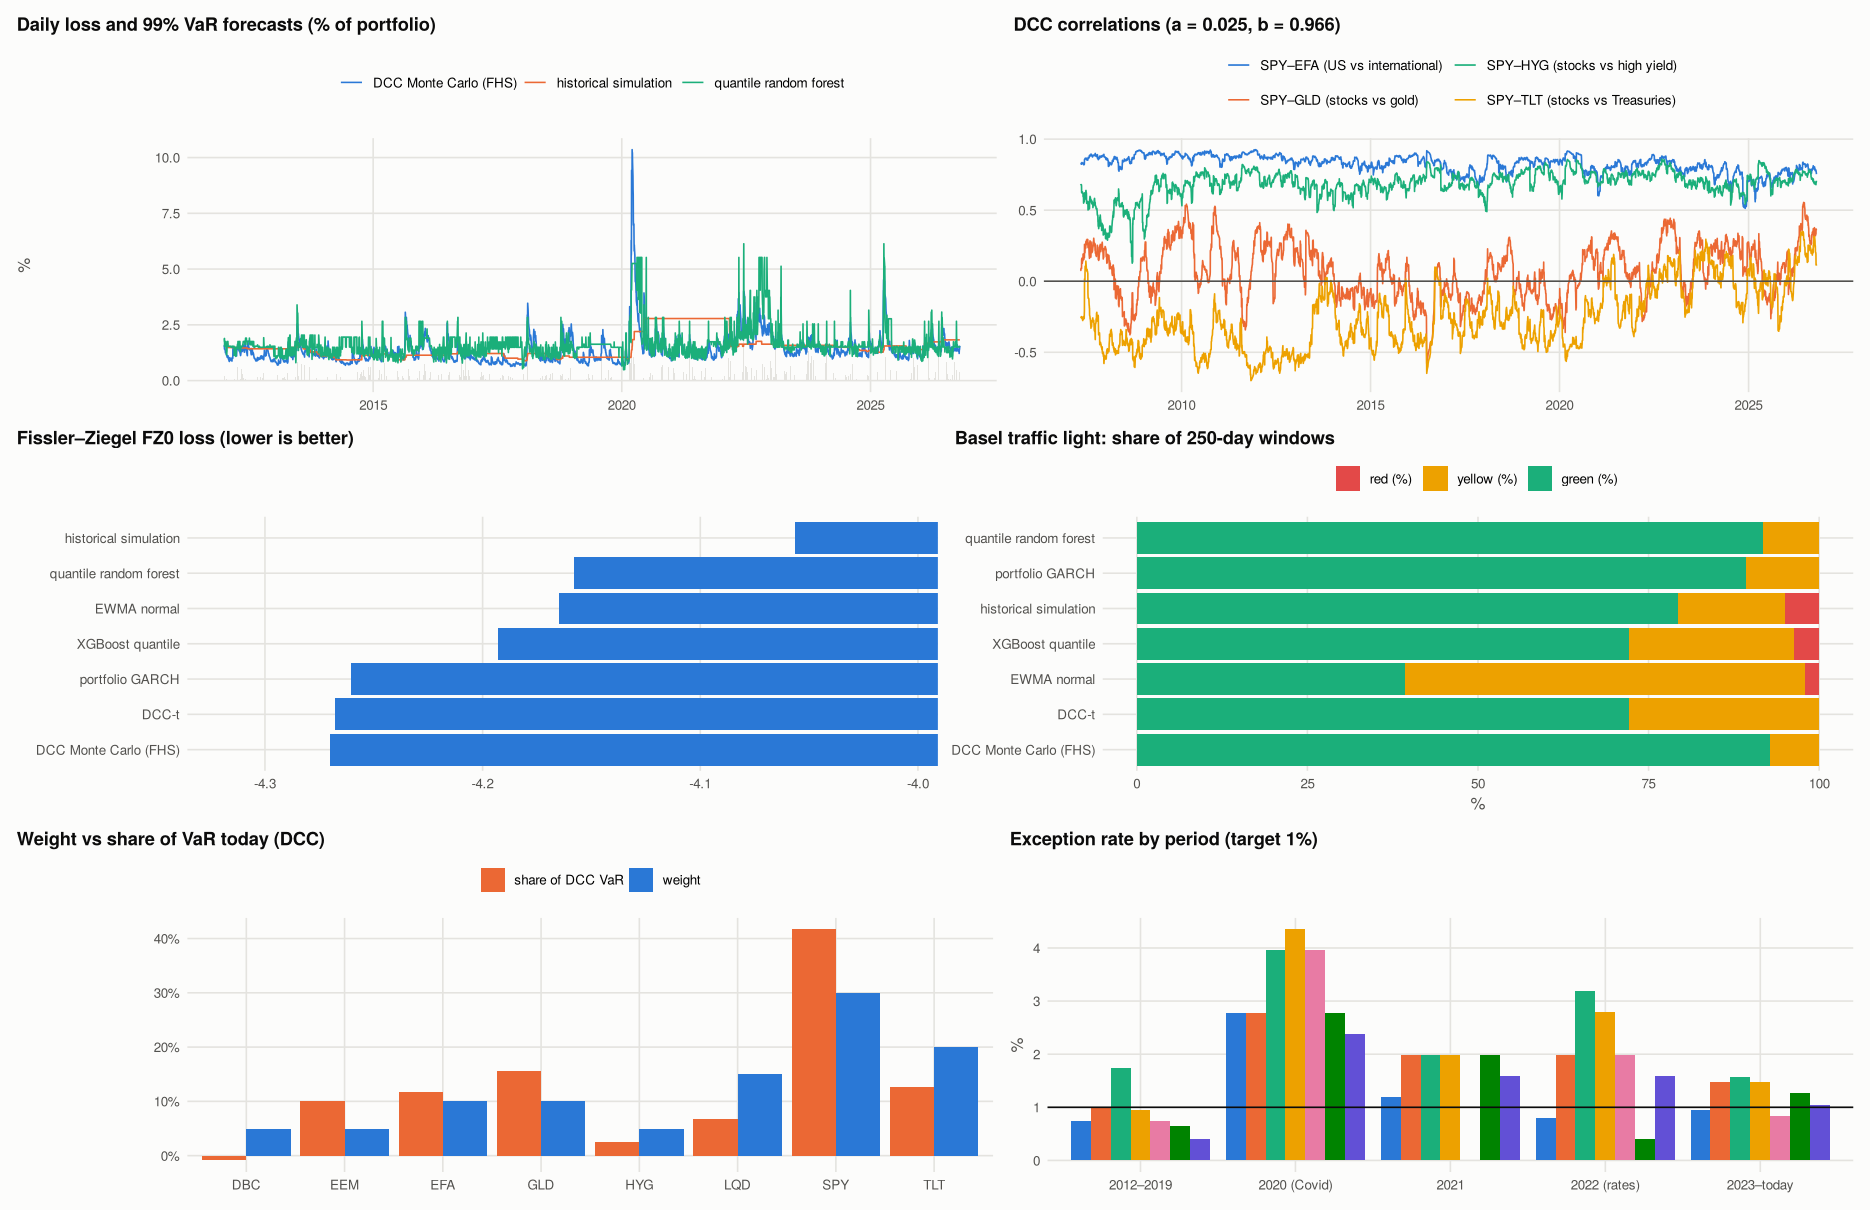

In [10]:
options(repr.plot.width = 17, repr.plot.height = 11)
vt <- tibble(
  date = dates[oos], loss = 100 * loss[oos], `historical simulation` = 100 *
    VaR[oos, 1], `DCC Monte Carlo (FHS)` = 100 * VaR[oos, 5],
  `quantile random forest` = 100 * VaR[oos, 6]
)
p1 <- vt |>
  pivot_longer(-c(date, loss), names_to = "model", values_to = "VaR") |>
  ggplot(aes(date)) +
  geom_col(data = vt, aes(y = pmax(loss, 0)), fill = GRID, width = 1) +
  geom_line(aes(y = VaR, colour = model), linewidth = 0.5) +
  scale_colour_manual(values = PALETTE[c(1, 2, 3)]) +
  labs(
    title = "Daily loss and 99% VaR forecasts (% of portfolio)", x = NULL,
    y = "%"
  )
p2 <- corr_ts |>
  pivot_longer(-date) |>
  ggplot(aes(date, value, colour = name)) +
  geom_line(linewidth = 0.5) +
  geom_hline(yintercept = 0, colour = INK_2) +
  scale_colour_manual(values = PALETTE[1:4]) +
  labs(
    title = sprintf("DCC correlations (a = %.3f, b = %.3f)", dcc_full$a,
                    dcc_full$b),
    x = NULL, y = NULL
  ) +
  guides(colour = guide_legend(nrow = 2))
p3 <- BT |>
  mutate(model = fct_reorder(model, FZ0)) |>
  ggplot(aes(model, FZ0)) +
  geom_col(fill = PALETTE[1]) +
  coord_flip(ylim = range(BT$FZ0) + c(-0.05, 0.05)) +
  labs(title = "Fissler–Ziegel FZ0 loss (lower is better)", x = NULL, y = NULL)
p4 <- BT |>
  select(model, `green (%)`, `yellow (%)`, `red (%)`) |>
  pivot_longer(-model) |>
  mutate(name = factor(name,
    levels = c("red (%)", "yellow (%)", "green (%)")
  )) |>
  ggplot(aes(model, value, fill = name)) +
  geom_col() +
  coord_flip() +
  scale_fill_manual(values = c(
    `green (%)` = STATUS[["green"]],
    `yellow (%)` = STATUS[["amber"]],
    `red (%)` = STATUS[["red"]]
  )) +
  labs(
    title = "Basel traffic light: share of 250-day windows", x = NULL,
    y = "%"
  )
p5 <- COMP |>
  pivot_longer(c(weight, `share of DCC VaR`)) |>
  ggplot(aes(asset, value, fill = name)) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = PALETTE[c(2, 1)]) +
  scale_y_continuous(labels = percent) +
  labs(title = "Weight vs share of VaR today (DCC)", x = NULL, y = NULL)
p6 <- SUB |>
  pivot_longer(-period, names_to = "model") |>
  ggplot(aes(period, value, fill = model)) +
  geom_col(position = "dodge") +
  geom_hline(yintercept = 1, colour = INK) +
  scale_fill_manual(values = PALETTE) +
  labs(title = "Exception rate by period (target 1%)", x = NULL, y = "%") +
  theme(legend.position = "none")
p <- (p1 | p2) / (p3 | p4) / (p5 | p6)
save_fig(p, "01_market_risk_engine", width = 17, height = 14)
print(p)

In [11]:
d1 <- plot_ly(vt, x = ~date) |>
  add_bars(
    y = ~ pmax(loss, 0), name = "loss (%)",
    marker = list(color = GRID)
  ) |>
  add_lines(
    y = ~`historical simulation`, name = "HS VaR",
    line = list(color = PALETTE[1], width = 1)
  ) |>
  add_lines(
    y = ~`DCC Monte Carlo (FHS)`, name = "DCC MC VaR",
    line = list(color = PALETTE[2], width = 1)
  ) |>
  add_lines(
    y = ~`quantile random forest`, name = "QRF VaR",
    line = list(color = PALETTE[3], width = 1)
  )
d2 <- plot_ly(corr_ts, x = ~date) |>
  add_lines(
    y = ~`SPY–TLT (stocks vs Treasuries)`, name = "SPY–TLT",
    line = list(color = PALETTE[1])
  ) |>
  add_lines(
    y = ~`SPY–HYG (stocks vs high yield)`, name = "SPY–HYG",
    line = list(color = PALETTE[3])
  )
d3 <- plot_ly(BT,
  x = ~model, y = ~`rate (%)`, type = "bar",
  name = "exception rate (%)", marker = list(color = PALETTE[4])
)
d4 <- plot_ly(COMP,
  x = ~asset, y = ~`component VaR ($k)`, type = "bar",
  name = "component VaR ($k)", marker = list(color = PALETTE[1])
)
dash <- subplot(d1, d2, d3, d4, nrows = 2, margin = 0.06, titleX = FALSE) |>
  layout(
    title = sprintf("Multi-asset market risk engine: 1-day 99%% VaR today $%.0fk (DCC Monte Carlo)",
                    VaR[n, 5] * NOTIONAL / 1e3),
    paper_bgcolor = SURFACE, plot_bgcolor = SURFACE
  )
save_plotly_html(dash, "dashboard", "Market risk engine")
save_fig(p1 / p2 / (p3 | p5), "dashboard", width = 15, height = 12)

Dashboard saved: outputs/dashboard.html



## 9. Reading the results and limitations

**What the data say**

- **The sample.** 4,898 trading days from May 2007 to October 2026. The 30/10/5/20/15/5/10/5 portfolio has an annualised volatility of 10.6%; its worst day was −6.1% on 12 March 2020. The out-of-sample test covers 3,720 days from 2012.
- **The filtered-historical-simulation Monte Carlo on DCC-GARCH is the best model on every count.**
  - 0.97% exceptions (Kupiec p 0.84);
  - no clustering (Christoffersen p 0.36);
  - green in 93% of the 250-day windows and never red;
  - an ES Z₂ statistic of −0.004, a tail almost exactly as forecast;
  - the lowest Fissler–Ziegel loss.

  The portfolio GARCH and the parametric DCC-t are close behind on FZ0. The DCC-t gets the shape right but slightly too thin (1.37% exceptions, Kupiec p 0.03).
- **The simple models fail in different ways.**
  - **EWMA with normal tails** has twice the expected exceptions (1.96%) and spends 59% of windows in the yellow zone.
  - **Historical simulation** gets the average rate right (1.02%) but its exceptions cluster (Christoffersen p ≈ 0): it is too slow after a regime change, and 5% of its windows are red.
- **The machine-learning models are respectable but not better.**
  - The **quantile random forest** passes the rate test (0.86%) and is green 92% of the time, but it is the most conservative model: average VaR $1.64mm against $1.39mm for the DCC Monte Carlo, and a negative Z₂ (−0.23). Its FZ0 is among the worst, because it carries more capital without adapting faster.
  - **XGBoost** quantile regression has too many exceptions (1.51%) and a tail that is too thin: its ES is barely above its 99% VaR, so quantile loss alone does not learn the extreme tail well with this much data.
  - With nine state variables and fifteen years of daily data, structure (GARCH dynamics plus correlation) beats flexibility.
- **Stress periods separate the models.** In 2020 every model breached too often: 3.95% exceptions for HS and EWMA, 2.8% for the GARCH family and 2.4% for the forest. In 2022, the year stocks and bonds fell together, EWMA reached 3.2% and HS 2.0%, while the DCC Monte Carlo (0.8%) and the portfolio GARCH (0.4%) stayed in bounds.

**The stock–bond hedge has broken.** The DCC correlation between SPY and long Treasuries was −0.45 to −0.50 in the 2008, 2011 and 2020 crises. It was −0.07 in 2022 and −0.09 in the April 2025 tariff shock, and it has averaged **+0.22 over the last three months**. Stocks and high yield stay highly correlated in every crisis (0.5–0.8). Correlation dynamics are persistent (a = 0.025, b = 0.966).

- **Today's risk.** The one-day 99% VaR on $100mm ranges from $1.13mm (EWMA) to $1.83mm (HS, still carrying older shocks); the best-performing model says **$1.56mm**, with an ES of $1.63mm. By Euler allocation:
  - SPY carries 42% of the risk with 30% of the weight;
  - gold carries 16% with 10% (its volatility is now 21%);
  - EEM carries 10% with 5%;
  - Treasuries add 13% instead of hedging;
  - only commodities (DBC) reduce risk, slightly.
- **Asymmetry is where the GARCH models expect it.** Equity volatility reacts almost only to falls: SPY's GJR term γ is 0.26 with α ≈ 0. Treasuries and gold show the opposite small asymmetry, since they tend to rally when stocks fall.

**Limitations**

- Fixed-weight, daily-rebalanced ETFs: no derivatives, no non-linear positions and no liquidity horizons. FRTB ES is computed over 10-day and longer horizons by liquidity bucket.
- The GARCH and DCC models are re-estimated every 63 days and the ML models yearly. More frequent re-estimation would help in fast regime changes, at a computing cost.
- The DCC is estimated in two steps with a Gaussian correlation likelihood. Asymmetric DCC, or models with a regime-dependent correlation target, are natural extensions.
- The FHS Monte Carlo resamples past standardised shocks, so it cannot produce a shock pattern never seen since 2007.
- The ML features are a small set of state variables; options data (skew, term structure) and order-flow measures could add information.

In [12]:
write_csv(BT, file.path(OUT_DIR, "backtest_by_model.csv"))
write_csv(SUB, file.path(OUT_DIR, "exception_rate_by_period.csv"))
write_csv(TODAY, file.path(OUT_DIR, "var_es_today.csv"))
write_csv(COMP, file.path(OUT_DIR, "component_var_today.csv"))
write_csv(crisis_tab, file.path(OUT_DIR, "dcc_correlation_in_crises.csv"))
write_csv(
  as_tibble(garch_tab, rownames = "asset"),
  file.path(OUT_DIR, "garch_parameters.csv")
)
write_csv(bind_cols(
  tibble(date = dates[oos], portfolio_return = rp[oos]),
  as_tibble(VaR[oos, ], .name_repair = ~ paste0("VaR99 ", MODELS)),
  as_tibble(ES[oos, ], .name_repair = ~ paste0("ES975 ", MODELS))
), file.path(OUT_DIR, "daily_forecasts.csv"))
cat(
  "Outputs written:", paste(sort(list.files(OUT_DIR)), collapse = ", "),
  "\n"
)

Outputs written: 01_market_risk_engine.png, backtest_by_model.csv, component_var_today.csv, daily_forecasts.csv, dashboard.html, dashboard.png, dcc_correlation_in_crises.csv, exception_rate_by_period.csv, garch_parameters.csv, var_es_today.csv 


## References

### Finance and regulation

- Engle, R. (2002). Dynamic conditional correlation: A simple class of multivariate generalized autoregressive conditional heteroskedasticity models. *Journal of Business & Economic Statistics, 20*(3), 339–350. https://doi.org/10.1198/073500102288618487
- Glosten, L. R., Jagannathan, R., & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *The Journal of Finance, 48*(5), 1779–1801. https://doi.org/10.1111/j.1540-6261.1993.tb05128.x
- Barone-Adesi, G., Giannopoulos, K., & Vosper, L. (1999). VaR without correlations for portfolios of derivative securities. *Journal of Futures Markets, 19*(5), 583–602. https://doi.org/10.1002/(SICI)1096-9934(199908)19:5<583::AID-FUT5>3.0.CO;2-S
- Basel Committee on Banking Supervision. (2019). *Minimum capital requirements for market risk*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d457.htm
- Patton, A. J., Ziegel, J. F., & Chen, R. (2019). Dynamic semiparametric models for expected shortfall (and value-at-risk). *Journal of Econometrics, 211*(2), 388–413. https://doi.org/10.1016/j.jeconom.2018.10.008

### Machine learning and deep learning

- Meinshausen, N. (2006). Quantile regression forests. *Journal of Machine Learning Research, 7*, 983–999. https://jmlr.org/papers/v7/meinshausen06a.html
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*. https://doi.org/10.1145/2939672.2939785
- Wright, M. N., & Ziegler, A. (2017). ranger: A fast implementation of random forests for high dimensional data in C++ and R. *Journal of Statistical Software, 77*(1), 1–17. https://doi.org/10.18637/jss.v077.i01